# Melbourne road repairs: which come first

The City of Melbourne publishes a condition rating for its road carriageway segments, from 1 (failed) to 5 (good). Plotlay puts it on its own scale on import, 1 (very good) to 5 (very poor), in a straight line (6 minus the council's value), so one scale runs through the roads and the sample buildings; the council's value is kept in `condition_council`. This notebook takes the 7,483 rated segments, works out the same repair priority score Plotlay gave them (0 to 100 from condition, road type, distance to a school or hospital and surface age, with stated weights), checks it against Plotlay's, then tries other weights and sums the repairs raised for the top 50.

The score is a prioritisation aid from the criteria and weights stated, not an engineering or condition assessment. Condition ratings are the council's. Costs are indicative, from published council asset plan rates.

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

seg = pd.read_csv('../data/road_segments.csv')
method = json.load(open('../data/method.json'))
print(len(seg), 'segments;', method['method'][:120], '...')
seg[['key', 'name', 'condition', 'condition_council', 'road_type', 'to_schools_and_hospitals_m', 'installed_age', 'priority_score']].head()

7483 segments; Priority score 0 to 100: the weighted mean of Condition 50% (higher values raise the priority, rescaled between 1 and 5) ...


,key,name,condition,condition_council,road_type,to_schools_and_hospitals_m,installed_age,priority_score
0,RD-0001,Henty Lane between Little Collins Street and S...,3.33,2.67,Council Minor,550,18.1,44.2
1,RD-0002,Little Bourke Street between Swanston Street a...,1.15,4.85,Council Major,527,1.5,17.8
2,RD-0003,Little Lonsdale Street between Exhibition Stre...,3.53,2.47,Council Major,176,6.0,57.4
3,RD-0004,McLean Alley between Sutherland Street and Gui...,3.16,2.84,Council Minor,498,26.7,46.8
4,RD-0005,Flinders Lane between Exhibition Street and Ru...,3.43,2.57,Council Major,414,18.0,55.0


## The criteria, rescaled

Each criterion is rescaled from 0 to 1, 1 being the highest priority:

- **Condition** (weight 50): between 1 and 5, lower ratings raise the priority.
- **Road type** (20): a number for each type from the council's road corridors (arterial 100, council major 70, council minor 40, private 10), rescaled between 0 and 100.
- **Near a school or hospital** (15): the distance to the nearest, between 0 and 600 m; closer raises the priority.
- **Surface age** (15): years since the surface was laid, between its 5th and 95th percentile over these segments.

Plotlay keeps each rescaled value to hundredths (the `driver_` columns, 0 to 100), so moving the weights later gives exactly the score a full run would.

In [2]:
crit = {c['id']: c for c in method['criteria']}

def fixed(v, lo, hi, lowers=False):
    t = ((v - lo) / (hi - lo)).clip(0, 1)
    return (1 - t if lowers else t).round(2)

n = pd.DataFrame(index=seg.index)
n['condition'] = fixed(seg['condition'], 1, 5)   # Plotlay's scale: 5 very poor, the highest priority
assert ((6 - seg['condition_council']).round(2) - seg['condition']).abs().max() < 0.006   # the conversion on import
road_map = crit['road_type']['map']
n['road_type'] = fixed(seg['road_type'].str.lower().map(road_map), 0, 100)
n['to_schools_and_hospitals_m'] = fixed(seg['to_schools_and_hospitals_m'], 0, 600, lowers=True)
b = crit['installed_age']['bounds']
n['installed_age'] = fixed(seg['installed_age'], b['lo'], b['hi'])

def score(weights):
    w = pd.Series(weights)
    have = n[w.index].notna()
    s = (n[w.index].fillna(0) * w).sum(axis=1) / (have * w).sum(axis=1)
    return (s * 100).round(1)

kept = {c['id']: c['weight'] for c in method['criteria']}
seg['mine'] = score(kept)
diff = (seg['mine'] - seg['priority_score']).abs()
print(f'largest difference from Plotlay: {diff.max():.2f} points; within 0.15 for {(diff <= 0.15).mean():.1%} of segments')

largest difference from Plotlay: 0.70 points; within 0.15 for 82.6% of segments


In [3]:
# the same sum from the rescaled values Plotlay kept (driver_ columns, 0 to 100): exact
d = seg[[f'driver_{k}' for k in kept]] / 100
d.columns = list(kept)
from_drivers = ((d.fillna(0) * pd.Series(kept)).sum(axis=1) / (d.notna() * pd.Series(kept)).sum(axis=1) * 100).round(1)
print(f"largest difference, from the kept drivers: {(from_drivers - seg['priority_score']).abs().max():.1f} points (the last digit's rounding)")

largest difference, from the kept drivers: 0.1 points (the last digit's rounding)


From the raw columns the scores differ slightly because the CSV rounds surface ages to 0.1 year and distances to 1 m after Plotlay rescaled them; from the kept drivers they agree to the last digit's rounding.

## The classes and the top 10

In [4]:
classes = pd.cut(seg['priority_score'], [-0.1, 20, 40, 60, 80, 100], labels=method['classes']['names'])
print(classes.value_counts().reindex(method['classes']['names']))
seg.sort_values('priority_rank')[['priority_rank', 'name', 'condition', 'condition_council', 'road_type', 'priority_score']].head(10)

priority_score
Very low      167
Low          1249
Medium       4756
High         1301
Very high      10
Name: count, dtype: int64


,priority_rank,name,condition,condition_council,road_type,priority_score
5954,1,Intersection of Bowen Crescent and Garton Street,4.70,1.30,Council Major,85.3
2228,2,Sutton Street between Boundary Road and Wester...,4.90,1.10,Council Major,85.0
4494,3,Nicholson Street between Spring Street and Alb...,4.33,1.67,Council Major,82.9
1359,4,Abbotsford Street between Brougham Street and ...,5.00,1.00,Council Major,82.8
5108,5,Intersection of Exhibition Street and Little L...,4.53,1.47,Council Major,82.6
3182,6,Wellington Parade between Hoddle Street and Si...,5.00,1.00,Arterial,82.3
5996,6,Pitt Street between Canning Street and Rathdow...,4.30,1.70,Council Major,82.3
1149,8,Wellington Parade between Hoddle Street and Si...,4.65,1.35,Arterial,80.5
1213,9,Cathedral Place between Lansdowne Street and G...,4.53,1.47,Council Major,80.4
2184,10,Intersection of Epsom Road and Kensington Road,4.30,1.70,Council Major,80.1


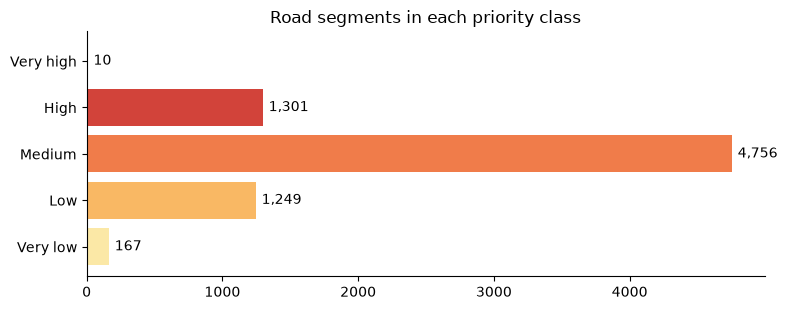

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.2))
counts = classes.value_counts().reindex(method['classes']['names'])
ax.barh(counts.index, counts.values, color=['#fbe8a6', '#f9b864', '#f07c4a', '#d2433a', '#8f1d3c'])
for y, v in enumerate(counts.values): ax.text(v + 40, y, f'{v:,}', va='center')
ax.set_title('Road segments in each priority class'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## Other weights

With condition alone, the worst-rated segments lead wherever they are. Only 34 segments are rated 4.5 or worse on Plotlay's scale (1.5 or lower on the council's) and 245 worse than 4, so with condition alone many share a score and the order among them is by key. How many of the top 50 stay in the top 50?

In [6]:
top = lambda s, k=50: set(seg.assign(s=s).sort_values(['s', 'key'], ascending=[False, True]).head(k)['key'])
alone = score({'condition': 100})
t_kept, t_alone = top(seg['priority_score']), top(alone)
print(f'{len(t_kept & t_alone)} of the top 50 are in both; {len(t_alone - t_kept)} enter with condition alone')

13 of the top 50 are in both; 37 enter with condition alone


## The repairs for the top 50

Plotlay raised one repair for each of the top 50 segments by its condition: reconstruction at 4.25 or worse on Plotlay's scale (1.75 or lower on the council's), resurfacing (mill and replace the wearing course) at 3.5 or worse, patching below. Each is counted in square metres of the segment and priced from the price book: resurfacing A$26 a square metre and reconstruction A$96 (Knox City Council's road asset plan, 2019), mid points of a range.

In [7]:
rep = pd.read_csv('../data/repairs.csv')
road = rep[rep['code'].str.startswith('rd.')]
print(road.groupby('code').agg(repairs=('ref', 'count'), m2=('qty', 'sum')))
print(f"priced in Plotlay at A${road['cost'].sum():,.0f} before the estimate's allowances")

                repairs     m2
code                          
rd.overlay           28  17792
rd.reconstruct       22  11031
priced in Plotlay at A$1,521,568 before the estimate's allowances


## The sample building, roof and gutter inspection

No council publishes building, roof and gutter inspections openly, so the repository also has a **made-up sample**: eight sites, each a building, its roof and its gutters, rated 1 (very good) to 5 (very poor) in the IPWEA style, scored on condition (60), time since inspection (20) and what the asset is (20).

In [8]:
s = pd.read_csv('../data/sample_inspection.csv')
s.sort_values('priority_rank')[['id', 'name', 'condition', 'last_inspected', 'priority_score', 'defects']].head(8)

,id,name,condition,last_inspected,priority_score,defects
10,RF-004,Sample site 4: roof,5,2026-01-15,97.2,DEF-0005 Sheets or tiles: Active leak over the...
2,GT-001,Sample site 1: gutter and downpipes,5,2026-02-15,91.4,"DEF-0002 Gutter: Outlets blocked, overflow sta..."
23,GT-008,Sample site 8: gutter and downpipes,5,2026-05-15,86.6,"DEF-0012 Gutter: Downpipe missing, water onto ..."
1,RF-001,Sample site 1: roof,4,2026-02-15,80.4,DEF-0001 Sheets or tiles: Cracked ridge cappin...
19,RF-007,Sample site 7: roof,4,2026-03-15,79.0,DEF-0009 Sheets or tiles: Broken tiles over th...
20,GT-007,Sample site 7: gutter and downpipes,4,2026-03-15,75.0,DEF-0010 Gutter: Gutter split at a joint (seve...
9,BLD-004,Sample site 4: building,4,2026-01-15,74.2,NaN
5,GT-002,Sample site 2: gutter and downpipes,4,2026-04-15,73.2,DEF-0004 Gutter: Gutter sagging at two bracket...
